# M3 experiments: train M3 (3 seeds) and the EXPLORATORY ablation (1 seed); Florence evaluation
Run order: inventory → m3_build_verify → **train_m3** → corruption → analysis

Run on: Colab **L4 GPU**. About 5.5-6 h in total (~4.75 h training, ~30 min Florence evaluation and attention analysis,
15 min data copy), roughly 26-29 compute units (estimate).

**Resumable.** After a disconnect, running the notebook again skips finished runs, and an unfinished run resumes from
its `last.pt` (the repo's own resume logic). Before any resume, the current `best.pt` is copied to `_resume_backups/`
next to that run's checkpoint folder, and every launch (start epoch, resumed or not, duration) is appended to
`logs/training_sessions.jsonl`.

Order: setup -> code -> data -> no-data loss check -> train (M3 s0, s1, s2, then the EXPLORATORY ablation s0) ->
checkpoint verification -> Florence evaluation -> attention analysis -> curves -> compute and summary.

Not done here: anything on Nepal, any corruption. Writes only inside `m3_experiments/`.

## 1. Setup

In [ ]:
# GPU check, Drive mount and project paths
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
import os, sys, json, time, hashlib, datetime, platform, shutil, math, subprocess, gc, random
from google.colab import drive
drive.mount("/content/drive")
D = "/content/drive/MyDrive/MAAI 902 X 901 PROJECT"
CK, EXTRAS = f"{D}/checkpoints", f"{D}/eval_extras"
EXP = f"{D}/m3_experiments"
X, MAN = "/content/xbd", "/content/xbd/rscc_flood_manifest.csv"
REPO, REPO_COMMIT, CODE = "/content/FloodVerify", "8f10e61", "/content/m3code"
# The inventory and build-and-verify notebooks must have run first
assert os.path.isdir(f"{EXP}/code"), "run Stages 2 and 3 first"
# out(): every path this notebook writes to is built here; anything outside m3_experiments/ raises
_EXP_REAL = os.path.realpath(EXP)
def out(*parts):
    p = os.path.realpath(os.path.join(EXP, *parts))
    if not (p == _EXP_REAL or p.startswith(_EXP_REAL + os.sep)):
        raise ValueError(f"refusing to write outside m3_experiments: {p}")
    return p
# Write JSON, converting numpy values to plain Python numbers
def jdump(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
# Size and modification time of every existing project file (read only)
def snapshot():
    snap = {}
    for name in sorted(os.listdir(D)):
        if name != "m3_experiments":
            snap[f"[top] {name}"] = os.path.getmtime(f"{D}/{name}")
    for root in (CK, EXTRAS, f"{D}/figures"):
        for dp, _, fs in os.walk(root):
            for fn in fs:
                st = os.stat(os.path.join(dp, fn)); snap[os.path.relpath(os.path.join(dp, fn), D)] = [st.st_size, st.st_mtime]
    return snap
# Snapshot before any work, session start time and GPU name
BEFORE = snapshot()
SESSION = {"session_start": datetime.datetime.now().isoformat(timespec="seconds"),
           "gpu": subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()}
# Output folders for this notebook
for s in ["m3/checkpoints/_verification", "m3/exploratory_ablation/checkpoints",
          "m3/exploratory_ablation/_verification", "m3/eval_val/reference_m1_ce", "m3/eval_val/EXPLORATORY_ablation",
          "results", "figures", "logs"]:
    os.makedirs(out(s), exist_ok=True)
print(SESSION)

name, memory.total [MiB], driver_version
NVIDIA L4, 23034 MiB, 580.82.07
Mounted at /content/drive
{'session_start': '2026-11-20T16:03:22', 'gpu': 'NVIDIA L4'}


## 2. Repository pinned to `main@8f10e61`

In [ ]:
# Fresh clone of the repository, pinned to commit 8f10e61 and installed in editable mode (not modified)
%cd /content
!rm -rf /content/FloodVerify
!git clone -q https://github.com/aaarrvind/FloodVerify.git /content/FloodVerify
%cd /content/FloodVerify
!git checkout -q 8f10e61 && git log -1 --format='%h %cd %s'
!pip install -q -e . --no-deps jsonschema
%cd /content
# Make the repo and the new M3 code folder importable
sys.path.insert(0, "/content/FloodVerify/src")

/content
/content/FloodVerify
8f10e61 Fri Nov 20 14:07:06 2026 +0400 Merge pull request #28 from aaarrvind/m5/generate-advisory
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for floodsitrep (pyproject.toml) ... done
/content


## 3. Code: the M3 modules from `m3_experiments/code/` (checked against their SHA-256), plus two new modules
The first cell copies the four files written by the build-and-verify notebook back to the Colab disk and checks each
against `code/MANIFEST.json`. The next two cells write two new files, `metrics_ext.py` and `m3_analysis.py`; the code in
those cells is exactly the code that ran.

In [ ]:
# Copy the earlier M3 code back to the Colab disk and check it against MANIFEST.json
os.makedirs(CODE, exist_ok=True); sys.path.insert(0, CODE)
def sha(p): return hashlib.sha256(open(p, "rb").read()).hexdigest()
MANI = json.load(open(out("code", "MANIFEST.json")))
for fn in ("m3_model.py", "m3_register.py", "train_m3.py", "m3_tests.py"):
    shutil.copy(out("code", fn), f"{CODE}/{fn}")
    assert sha(f"{CODE}/{fn}") == MANI["files"][fn], f"{fn} differs from the Stage 3 version"
print("Stage 3 code verified:", list(MANI["files"]))

Stage 3 code verified: ['m3_model.py', 'm3_register.py', 'm3_tests.py', 'train_m3.py']


### `metrics_ext.py`: extended metrics
Works on the repo's 5x5 pixel confusion matrices and adds metrics without changing any existing definition: building
IoU, background IoU and binary mIoU; damage macro-F1 (the plain mean of the four damage F1s, each counted exactly as the
repo's damage F1, over ground-truth building pixels); per-class precision, recall and F1 for the 5-class segmentation
and for the damage classes; and a percentile bootstrap over crops (`bootstrap_extended`). `extended()` asserts that
every damage F1 equals the repo's own value.

In [ ]:
%%writefile /content/m3code/metrics_ext.py
"""Extended metrics from the repo's 5x5 PIXEL confusion matrices (rows = truth, columns = prediction).

Adds, without changing any existing definition in floodsitrep.cv.eval.metrics:
- building_iou: building (classes 1-4) vs background, IoU of the BUILDING class: TP/(TP+FP+FN)
- background_iou: IoU of the background class in the same binary split
- binary_miou: mean of the two (reported separately from building_iou)
- damage_macro_f1: plain mean of the four damage F1s, each computed exactly as the repo's damage_f1
  (ground-truth building pixels only; a building pixel predicted as background is a false negative
  of its true class; background-row pixels never count as false positives)
- per-class precision / recall / F1, two families:
    px5_<class>_*:  5-class semantic segmentation over all valid pixels
    dmg_<class>_*:  damage classes over ground-truth building pixels (same counts as damage_f1)
The repo's own numbers (xview2_pixel_score, loc_f1, damage_f1_hm, miou, ...) are passed through
unchanged; every damage F1 is asserted equal to the repo's value.
"""
import numpy as np

from floodsitrep.cv.eval import metrics as M

NAMES = M.CLASS_NAMES
DAMAGE_NAMES = NAMES[1:]


def _div(a, b):
    return float(a / b) if b > 0 else float("nan")


def _prf(tp, fp, fn):
    return _div(tp, tp + fp), _div(tp, tp + fn), _div(2 * tp, 2 * tp + fp + fn)


def binary_iou(cm):
    cm = np.asarray(cm, dtype=np.float64)
    tp, fp, fn, tn = cm[1:, 1:].sum(), cm[0, 1:].sum(), cm[1:, 0].sum(), cm[0, 0]
    bld = _div(tp, tp + fp + fn)
    bg = _div(tn, tn + fn + fp)
    vals = [v for v in (bld, bg) if not np.isnan(v)]
    return {"building_iou": bld, "background_iou": bg,
            "binary_miou": float(np.mean(vals)) if vals else float("nan")}


def per_class_prf(cm):
    """5-class precision/recall/F1 over all valid pixels."""
    cm = np.asarray(cm, dtype=np.float64)
    out = {}
    for k, n in enumerate(NAMES):
        tp = cm[k, k]
        p, r, f = _prf(tp, cm[:, k].sum() - tp, cm[k, :].sum() - tp)
        out[n] = {"precision": p, "recall": r, "f1": f, "support_px": int(cm[k, :].sum())}
    return out


def damage_prf(cm):
    """Damage precision/recall/F1 over ground-truth building pixels (the repo's damage_f1 counts)."""
    cm = np.asarray(cm, dtype=np.float64)
    out = {}
    for c in (1, 2, 3, 4):
        tp = cm[c, c]
        fn = cm[c, :].sum() - tp            # includes building pixels predicted as background
        fp = cm[1:, c].sum() - tp           # background rows excluded
        p, r, f = _prf(tp, fp, fn)
        out[NAMES[c]] = {"precision": p, "recall": r, "f1": f, "support_px": int(cm[c, :].sum())}
    return out


def extended(cm):
    """Flat dict: the repo's M.flat(M.summarise(cm)) plus the additions listed in the module docstring."""
    s = M.flat(M.summarise(cm))
    out = dict(s)
    out.update(binary_iou(cm))
    d = damage_prf(cm)
    for n in DAMAGE_NAMES:
        ref = s[f"dmg_f1_{n}"]
        if not (np.isnan(ref) and np.isnan(d[n]["f1"])):
            assert abs(ref - d[n]["f1"]) < 1e-12, f"damage F1 mismatch for {n}"
    f1s = [d[n]["f1"] for n in DAMAGE_NAMES]
    out["damage_macro_f1"] = float(np.mean(f1s)) if not any(np.isnan(f1s)) else float("nan")
    for n in DAMAGE_NAMES:
        for k in ("precision", "recall", "f1"):
            out[f"dmg_{n}_{k}"] = d[n][k]
    for n, v in per_class_prf(cm).items():
        for k in ("precision", "recall", "f1"):
            out[f"px5_{n}_{k}"] = v[k]
    return out


def bootstrap_extended(tile_cms, keys, n_boot=1000, seed=0, alpha=0.05):
    """Percentile bootstrap over TILES (crops) for selected keys of ``extended``."""
    cms = np.asarray(tile_cms, dtype=np.int64)
    point = extended(cms.sum(0))
    rng = np.random.default_rng(seed)
    draws = {k: [] for k in keys}
    for _ in range(n_boot):
        e = extended(cms[rng.integers(0, len(cms), len(cms))].sum(0))
        for k in keys:
            draws[k].append(e[k])
    out = {}
    for k in keys:
        a = np.array([x for x in draws[k] if not np.isnan(x)])
        lo, hi = np.quantile(a, [alpha / 2, 1 - alpha / 2]) if len(a) else (float("nan"),) * 2
        out[k] = {"value": point[k], "lo": float(lo), "hi": float(hi)}
    return out

Writing /content/m3code/metrics_ext.py


### `m3_analysis.py`: run verification and attention analysis
- `verify_run(run_dir, expect)`: checks that `best.pt`, `last.pt`, `config.yaml` and `metrics.jsonl` exist, load
  strictly, describe the same completed 20-epoch run, and match the approved recipe.
- `attention_analysis(model, ...)`: on Florence only, reports the learned `gamma` of each attention scale, the size of
  the attention update relative to the post features, channel- and spatial-gate statistics at all five scales, and a
  knock-out test (`gamma` set to 0 at inference) with the resulting change in predictions and metrics.

In [ ]:
%%writefile /content/m3code/m3_analysis.py
"""Stage 4 helpers: run verification and attention analysis. Florence (validation) only.

verify_run(run_dir, expect)      best.pt, last.pt, config.yaml, metrics.jsonl exist, load (strict) and agree
attention_analysis(model, ...)   learned gamma per attention scale, size of the attention update relative to
                                 the post features, channel/spatial gate statistics at all 5 scales, and an
                                 inference-time knock-out (gamma set to 0) with the change in predictions/metrics
"""
import hashlib
import json
import math
import os

import numpy as np
import torch


def _sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def _same(a, b):
    if isinstance(b, float) and isinstance(a, (int, float)) and not isinstance(a, bool):
        return math.isclose(a, b, rel_tol=1e-9, abs_tol=0.0)
    return a == b


def verify_run(run_dir, expect, epochs=20):
    """Checks that the four files of a finished run exist, load, and describe the same completed run."""
    import yaml

    from floodsitrep.cv.models import build_model, load_checkpoint

    r, issues = {"run_dir": run_dir}, []
    names = ("best.pt", "last.pt", "config.yaml", "metrics.jsonl")
    r["files_present"] = {f: os.path.exists(os.path.join(run_dir, f)) for f in names}
    if not all(r["files_present"].values()):
        r["issues"] = ["missing files: " + ", ".join(f for f, ok in r["files_present"].items() if not ok)]
        r["status"] = "FAILED"
        return r
    rows = [json.loads(line) for line in open(os.path.join(run_dir, "metrics.jsonl"))]
    ep = [x["epoch"] for x in rows]
    r["metrics_lines"] = len(rows)
    if ep != list(range(epochs)):
        issues.append(f"metrics.jsonl epochs {ep}: expected 0..{epochs - 1}, each once, in order")
    sel = [0.0 if x["xview2_pixel_score"] is None or math.isnan(x["xview2_pixel_score"]) else x["xview2_pixel_score"]
           for x in rows]
    i_best = int(np.argmax(sel))                       # first maximum = train.py's strict '>' update rule
    r["log_best_epoch"], r["log_best_score"] = ep[i_best], sel[i_best]
    best = torch.load(os.path.join(run_dir, "best.pt"), map_location="cpu", weights_only=False)
    last = torch.load(os.path.join(run_dir, "last.pt"), map_location="cpu", weights_only=False)
    for k in ("model", "config", "epoch", "val"):
        if k not in best:
            issues.append(f"best.pt lacks '{k}'")
    for k in ("model", "optimizer", "scheduler", "scaler", "epoch", "best", "config", "val"):
        if k not in last:
            issues.append(f"last.pt lacks '{k}'")
    r.update({"best_pt_epoch": int(best["epoch"]), "best_pt_val_score": float(best["val"]["xview2_pixel_score"]),
              "last_pt_epoch": int(last["epoch"]), "last_pt_best": float(last["best"]),
              "best_pt_sha256": _sha256(os.path.join(run_dir, "best.pt")),
              "best_pt_MB": round(os.path.getsize(os.path.join(run_dir, "best.pt")) / 1e6, 1),
              "last_pt_MB": round(os.path.getsize(os.path.join(run_dir, "last.pt")) / 1e6, 1)})
    if r["last_pt_epoch"] != epochs - 1:
        issues.append(f"last.pt is epoch {r['last_pt_epoch']}, expected {epochs - 1} (run not complete)")
    if r["best_pt_epoch"] != r["log_best_epoch"]:
        issues.append(f"best.pt epoch {r['best_pt_epoch']} != best epoch in metrics.jsonl {r['log_best_epoch']}")
    if not math.isclose(r["best_pt_val_score"], r["log_best_score"], abs_tol=1e-12):
        issues.append("best.pt validation score differs from the metrics.jsonl maximum")
    if not math.isclose(r["last_pt_best"], r["log_best_score"], abs_tol=1e-12):
        issues.append("last.pt 'best' differs from the metrics.jsonl maximum")
    if best["val"].get("val_confusion") != rows[i_best].get("val_confusion"):
        issues.append("best.pt validation confusion matrix differs from the metrics.jsonl line of that epoch")
    y = yaml.safe_load(open(os.path.join(run_dir, "config.yaml")))
    cb, cl = best["config"], last["config"]
    dif_y = [k for k in y if k != "encoder_config" and (y[k] != cb.get(k) or y[k] != cl.get(k))]
    if dif_y:
        issues.append("config.yaml / best.pt / last.pt configs differ on: " + ", ".join(dif_y))
    for k, v in expect.items():
        if not _same(cb.get(k, "<absent>"), v):
            issues.append(f"config {k}: expected {v!r}, got {cb.get(k, '<absent>')!r}")
    try:
        load_checkpoint(os.path.join(run_dir, "best.pt"), "cpu")       # strict load
        m = build_model(cl, pretrained=False)
        m.load_state_dict(last["model"])                                # strict load
        r["loads_strict"] = True
    except Exception as e:
        r["loads_strict"] = False
        issues.append(f"strict load failed: {e!r}")
    r["epoch_seconds_logged_total"] = float(sum(x.get("seconds", 0.0) for x in rows))
    r["issues"] = issues
    r["status"] = "OK" if not issues else "CHECK"
    return r


@torch.no_grad()
def attention_analysis(model, xbd_root, manifest, device, batch_size=16, num_workers=8, limit=0):
    """Florence (val) only. Returns gamma, attention-update size, gate statistics and a knock-out table."""
    from torch.utils.data import DataLoader

    from floodsitrep.cv.eval import metrics as M
    from floodsitrep.cv.eval.infer import make_dataset
    from m3_model import CrossTemporalAttention, MSTAUNet
    from metrics_ext import extended

    device = torch.device(device)
    ds = make_dataset(xbd_root, manifest, "val", limit, sort=True)
    assert {r["event"] for r in ds.rows} == {"hurricane-florence"}, "attention analysis is Florence-only"
    dl = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    model.eval()
    att_idx = list(MSTAUNet.ATTENTION_SCALES)
    strides = (2, 4, 8, 16, 32)
    gammas = {i: float(model.fuse[i].gamma) for i in att_idx}
    rel = {i: [] for i in att_idx}
    gate = {i: {"ch": [0.0, 0.0, 0, math.inf, -math.inf], "sp": [0.0, 0.0, 0, math.inf, -math.inf], "sp_gt_0.5": 0}
            for i in range(5)}
    active, cache, handles = {"on": True}, {}, []

    def acc(slot, v):
        slot[0] += float(v.sum()); slot[1] += float((v * v).sum()); slot[2] += v.numel()
        slot[3] = min(slot[3], float(v.min())); slot[4] = max(slot[4], float(v.max()))

    for i in range(5):
        f = model.fuse[i]
        loc = f.local if isinstance(f, CrossTemporalAttention) else f

        def ch_hook(mod, inp, out, i=i):
            if active["on"]:
                acc(gate[i]["ch"], out.float())

        def sp_hook(mod, inp, out, i=i):
            if active["on"]:
                v = out.float()
                acc(gate[i]["sp"], v)
                gate[i]["sp_gt_0.5"] += int((v > 0.5).sum())

        handles += [loc.channel_att.register_forward_hook(ch_hook), loc.spatial_gate.register_forward_hook(sp_hook)]
    for i in att_idx:
        cta = model.fuse[i]

        def pre_hook(mod, args, i=i):
            if active["on"]:
                cache[i] = args[1]                                     # post features entering the module

        def att_hook(mod, inp, out, i=i):
            if active["on"]:
                att = out[0].float()                                   # [B, N, C]
                p = cache.pop(i).float().flatten(2).transpose(1, 2)    # [B, N, C]
                num = (float(model.fuse[i].gamma) * att).flatten(1).norm(dim=1)
                den = p.flatten(1).norm(dim=1).clamp_min(1e-12)
                rel[i].extend((num / den).cpu().tolist())

        handles += [cta.register_forward_pre_hook(pre_hook), cta.attn.register_forward_hook(att_hook)]

    variants = {"full model": [], "attention off at stride 16": [3], "attention off at stride 32": [4],
                "attention off at both": [3, 4]}
    cms = {v: np.zeros((5, 5), np.int64) for v in variants}
    changed = {v: 0 for v in variants}
    n_valid = 0
    amp = device.type == "cuda"
    try:
        for b in dl:
            pre, post = b["pre"].to(device, non_blocking=True), b["post"].to(device, non_blocking=True)
            mask, valid = b["mask"].numpy(), b["valid"].numpy()
            preds = {}
            for v, off in variants.items():
                active["on"] = v == "full model"
                saved = {i: model.fuse[i].gamma.detach().clone() for i in off}
                for i in off:
                    model.fuse[i].gamma.zero_()
                with torch.autocast(device.type, enabled=amp):
                    preds[v] = model(pre, post).argmax(1).cpu().numpy()
                for i in off:
                    model.fuse[i].gamma.copy_(saved[i])
            keep = valid & (mask <= 4)
            n_valid += int(keep.sum())
            for v in variants:
                cms[v] += M.confusion(preds[v], mask, valid)
                changed[v] += int(((preds[v] != preds["full model"]) & keep).sum())
    finally:
        for h in handles:
            h.remove()
        active["on"] = True

    def summ(slot):
        s, sq, n, lo, hi = slot
        mean = s / n
        return {"mean": mean, "std": math.sqrt(max(sq / n - mean * mean, 0.0)), "min": lo, "max": hi}

    full = extended(cms["full model"])
    knock = []
    for v in variants:
        e = extended(cms[v])
        knock.append({"variant": v, "pixels_changed_vs_full": changed[v], "share_changed": changed[v] / max(n_valid, 1),
                      **{k: e[k] for k in ("xview2_pixel_score", "loc_f1", "damage_macro_f1", "building_iou",
                                           "dmg_f1_destroyed")},
                      "delta_xview2_vs_full": e["xview2_pixel_score"] - full["xview2_pixel_score"],
                      "delta_macro_f1_vs_full": e["damage_macro_f1"] - full["damage_macro_f1"]})
    scales = []
    for i in range(5):
        row = {"scale_index": i, "stride": strides[i],
               "attention_branch": i in att_idx,
               "gamma": gammas.get(i, "no attention branch at this scale (local fusion only)")}
        if i in att_idx:
            a = np.array(rel[i])
            row.update({"attention_update_rel_norm_mean": float(a.mean()), "attention_update_rel_norm_median": float(np.median(a)),
                        "attention_update_rel_norm_p95": float(np.quantile(a, 0.95))})
        ch, sp = summ(gate[i]["ch"]), summ(gate[i]["sp"])
        row.update({f"channel_gate_{k}": v for k, v in ch.items()})
        row.update({f"spatial_gate_{k}": v for k, v in sp.items()})
        row["spatial_gate_share_above_0.5"] = gate[i]["sp_gt_0.5"] / max(gate[i]["sp"][2], 1)
        scales.append(row)
    return {"crops": len(ds), "valid_pixels": n_valid, "scales": scales, "knockout": knock}

Writing /content/m3code/m3_analysis.py


### Save the new code and load all modules
Copies the two new files to `m3_experiments/code/` (an older, different version is moved to `code/_previous/`), adds
their hashes to `MANIFEST.json`, registers the new models, and checks that `metrics_ext` reproduces the repo's score on
a logged M1 confusion matrix.

In [ ]:
# Save the two new files to m3_experiments/code/ and record their hashes
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
for fn in ("metrics_ext.py", "m3_analysis.py"):
    dst = out("code", fn)
    if os.path.exists(dst) and sha(dst) != sha(f"{CODE}/{fn}"):
        shutil.move(dst, out("code", "_previous", f"{fn[:-3]}.{stamp}.py"))
    if not os.path.exists(dst):
        shutil.copy(f"{CODE}/{fn}", dst)
    MANI["files"][fn] = sha(f"{CODE}/{fn}")
MANI["updated_stage4"] = stamp
jdump(MANI, out("code", "MANIFEST.json"))
# Load all modules and register the new models
import importlib, torch, numpy as np, pandas as pd
import m3_model, m3_register, metrics_ext, m3_analysis
for m in (m3_model, m3_register, metrics_ext, m3_analysis): importlib.reload(m)
m3_register.register()
from floodsitrep.cv.models import build_model, load_checkpoint
from floodsitrep.cv.eval import metrics as M
import floodsitrep.cv.eval.building_level as B
# extended metrics reproduce the repo's numbers on a real logged matrix (M1 CE s0, best epoch): read-only
rows = [json.loads(l) for l in open(f"{CK}/m1_siamese_unet_ce_s0/metrics.jsonl")]
bl = max(rows, key=lambda r: r["xview2_pixel_score"])
e = metrics_ext.extended(np.array(bl["val_confusion"]))
print("M1 CE s0 best epoch", bl["epoch"], "| repo score", round(bl["xview2_pixel_score"], 4), "| via metrics_ext",
      round(e["xview2_pixel_score"], 4), "| building IoU", round(e["building_iou"], 4), "| damage macro-F1",
      round(e["damage_macro_f1"], 4))
assert abs(e["xview2_pixel_score"] - bl["xview2_pixel_score"]) < 1e-12

M1 CE s0 best epoch 12 | repo score 0.3633 | via metrics_ext 0.3633 | building IoU 0.6421 | damage macro-F1 0.3353


## 4. Data to local disk (same commands as the training notebooks) and a file check

In [ ]:
# Extract the training data and copy the validation and test folders (skipped if already present)
if not os.path.exists(f"{X}/hold"):
    !mkdir -p /content/xbd
    !tar -xf "{D}/xbd_tars/train_images_labels_targets.tar" -C /content/xbd
    !tar -xf "{D}/xbd_tars/test_images_labels_targets.tar" -C /content/xbd
    !cp -r "{D}/xbd/hold" /content/xbd/
    !cp -r "{D}/xbd/tier3" /content/xbd/
    !cp "{D}/xbd/rscc_flood_manifest.csv" /content/xbd/
# Every training and Florence crop must have its pre, post, target and label files
from floodsitrep.data.dataset import XbdTiles
from floodsitrep.data.tiling import source_paths, load_crop, tile_name
for role in ("train", "val"):
    ds = XbdTiles(X, MAN, role=role)
    miss = sum(not all(os.path.exists(source_paths(X, r)[k]) for k in ("pre", "post", "target", "label")) for r in ds.rows)
    print(role, len(ds), "crops, missing files:", miss)
    assert miss == 0

train 5488 crops, missing files: 0
val 2184 crops, missing files: 0


## 5. Loss-split check on REAL crops with no-data pixels
Florence crops are picked from the earlier cloud screen (`eval_extras/cloud_screen_val_test.csv`, read only:
`valid_fraction` < 1) and training crops by scanning in a fixed random order; each is re-checked by loading it. M3 at its
starting weights (seed 0). Compared: the exact training-loss call vs the two-head decomposition (float32 and float64),
the weighted-mean denominator, and the loss after changing the model outputs at ignored pixels.

In [ ]:
from torch.utils.data import default_collate
import torch.nn.functional as F
from floodsitrep.cv.train import prepare_target
from floodsitrep.cv.models.losses import SegLoss
from m3_model import combine_heads, decomposed_weighted_ce, M3_CLASS_WEIGHTS as W
DEV = torch.device("cuda")
VAL_DS, TR_DS = XbdTiles(X, MAN, role="val"), XbdTiles(X, MAN, role="train")
# Florence crops with partial no-data, taken from the earlier cloud screen (read only)
picked = []
cs = f"{EXTRAS}/cloud_screen_val_test.csv"
if os.path.exists(cs):
    S = pd.read_csv(cs)
    S = S[(S.event == "hurricane-florence") & (S.valid_fraction < 0.999) & (S.valid_fraction > 0.05)].sort_values("valid_fraction")
    vidx = {tile_name(r): i for i, r in enumerate(VAL_DS.rows)}
    picked += [("val", vidx[t]) for t in list(S.tile)[:4] if t in vidx]
# Training crops with partial no-data, found by scanning in a fixed random order
order = random.Random(0).sample(range(len(TR_DS)), len(TR_DS))
n_tr = 0
for i in order[:1500]:
    _, _, _, v = load_crop(X, TR_DS.rows[i])
    if 0.05 < v.mean() < 0.999:
        picked.append(("train", i)); n_tr += 1
        if n_tr == 4: break
items = [(VAL_DS if role == "val" else TR_DS)[i] for role, i in picked]
assert items, "no crops with no-data pixels found"
# One batch of these crops and its training target (255 = ignored)
batch = default_collate(items)
tgt = prepare_target(batch, DEV)
# Per crop: valid fraction, no-data pixels and pixels per class
CROPS = []
for k, (role, _) in enumerate(picked):
    v, m = batch["valid"][k], batch["mask"][k]
    CROPS.append({"crop_id": batch["tile_id"][k], "role": role, "valid_fraction": float(v.float().mean()),
                  "no_data_px": int((~v).sum()), "label_gt4_px_on_valid": int(((m > 4) & v).sum()),
                  "ignored_px_in_target (255)": int((tgt[k] == 255).sum()),
                  "px_per_class": [int((tgt[k] == c).sum()) for c in range(5)]})
# M3 at its starting weights produces the two head outputs
torch.manual_seed(0)
m3 = build_model({"model": "m3_msta_unet", "pretrained": True}).to(DEV).eval()
with torch.no_grad(), torch.autocast("cuda"):
    zb, zd = m3.forward_heads(batch["pre"].to(DEV), batch["post"].to(DEV))
zb, zd = zb.float(), zd.float()
# The training-loss call vs the two-head decomposition, in float32 and float64
loss_fn = SegLoss("ce", W)
ign = tgt == 255
call32 = float(loss_fn(combine_heads(zb, zd), tgt))
dec32 = decomposed_weighted_ce(zb, zd, tgt, W)
zb64, zd64 = zb.double(), zd.double()
ref64 = float(F.cross_entropy(combine_heads(zb64, zd64), tgt, weight=torch.tensor(W, dtype=torch.float64, device=DEV), ignore_index=255))
dec64 = decomposed_weighted_ce(zb64, zd64, tgt, W)
wsum = float(torch.tensor(W, dtype=torch.float64, device=DEV)[tgt.clamp(0, 4)][~ign].sum())
# Change the outputs only at ignored pixels: the loss must not change
zb2 = torch.where(ign.unsqueeze(1), zb + 50.0, zb)
zd2 = torch.where(ign.unsqueeze(1).expand_as(zd), -5.0 * zd, zd)
call32_pert = float(loss_fn(combine_heads(zb2, zd2), tgt))
# exact invariance test in float64 on the CPU (deterministic reduction); GPU fp32 difference reported alongside
t_cpu, w64 = tgt.cpu(), torch.tensor(W, dtype=torch.float64)
ce64_cpu = F.cross_entropy(combine_heads(zb64.cpu(), zd64.cpu()), t_cpu, weight=w64, ignore_index=255)
ce64_cpu_pert = F.cross_entropy(combine_heads(zb2.double().cpu(), zd2.double().cpu()), t_cpu, weight=w64, ignore_index=255)
# Collect the results; PASS requires every check to hold
NODATA = {"crops": CROPS, "total_ignored_px": int(ign.sum()),
          "train-loss call SegLoss('ce') fp32": call32, "decomposed fp32": float(dec32["total"]),
          "CE fp64": ref64, "decomposed fp64": float(dec64["total"]),
          "building term / damage term (fp64)": [float(dec64["building_term"]), float(dec64["damage_term"])],
          "denominator decomposed / explicit sum w_y over non-ignored": [float(dec64["denominator"]), wsum],
          "|decomposed - CE| fp64": abs(float(dec64["total"]) - ref64),
          "rel |fp32 call - decomposed fp32|": abs(call32 - float(dec32["total"])) / call32,
          "loss change after altering outputs at ignored pixels (fp64, CPU)": abs(float(ce64_cpu_pert) - float(ce64_cpu)),
          "loss change after altering outputs at ignored pixels (fp32, GPU; reduction order may vary)": abs(call32_pert - call32)}
NODATA["PASS"] = (NODATA["total_ignored_px"] > 0 and NODATA["|decomposed - CE| fp64"] < 1e-10
                  and NODATA["rel |fp32 call - decomposed fp32|"] < 1e-5 and abs(float(dec64["denominator"]) - wsum) < 1e-6
                  and NODATA["loss change after altering outputs at ignored pixels (fp64, CPU)"] == 0.0
                  and NODATA["loss change after altering outputs at ignored pixels (fp32, GPU; reduction order may vary)"] <= 1e-6 * call32)
jdump(NODATA, out("m3", "benchmark", "nodata_loss_check.json"))
print(json.dumps(NODATA, indent=1))
del m3; gc.collect(); torch.cuda.empty_cache()
assert NODATA["PASS"]

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 239MB/s]


{
 "crops": [
  {
   "crop_id": "hurricane-florence_00000140_p1",
   "role": "val",
   "valid_fraction": 0.055980682373046875,
   "no_data_px": 247469,
   "label_gt4_px_on_valid": 0,
   "ignored_px_in_target (255)": 247469,
   "px_per_class": [
    14675,
    0,
    0,
    0,
    0
   ]
  },
  {
   "crop_id": "hurricane-florence_00000341_p4",
   "role": "val",
   "valid_fraction": 0.056285858154296875,
   "no_data_px": 247389,
   "label_gt4_px_on_valid": 0,
   "ignored_px_in_target (255)": 247389,
   "px_per_class": [
    14755,
    0,
    0,
    0,
    0
   ]
  },
  {
   "crop_id": "hurricane-florence_00000138_p4",
   "role": "val",
   "valid_fraction": 0.06889724731445312,
   "no_data_px": 244083,
   "label_gt4_px_on_valid": 0,
   "ignored_px_in_target (255)": 244083,
   "px_per_class": [
    18061,
    0,
    0,
    0,
    0
   ]
  },
  {
   "crop_id": "hurricane-florence_00000140_p3",
   "role": "val",
   "valid_fraction": 0.08444595336914062,
   "no_data_px": 240007,
   "label_gt4

## 6. Training
Each run: if `last.pt` is at epoch 19 and `metrics.jsonl` has 20 epochs, it is skipped. Otherwise the start epoch is read
from `last.pt` (0 if none), `best.pt` is backed up if this is a resume, and the unchanged `train.py` is launched through
`code/train_m3.py` with the approved config; the console output streams below and is saved to `logs/`. After each run:
verification of `best.pt`, `last.pt`, `config.yaml` and `metrics.jsonl` (exist, strict load, same config, best epoch and
score consistent across the four files, recipe as approved).

In [ ]:
from m3_analysis import verify_run
# The approved recipe; every finished run is checked against it
RECIPE = {"loss": "ce", "class_weights": W, "epochs": 20, "batch_size": 8, "lr": 3e-4, "weight_decay": 1e-4,
          "warmup_steps": 200, "amp": True, "encoder_lr_mult": 1.0, "grad_clip": 1.0, "max_train_tiles": 0,
          "max_val_tiles": 0, "n_classes": 5}
# The four training runs
RUNS = [  # (run name, group, config file, seed, output folder)
    ("m3_msta_unet_ce_s0", "M3 (primary)", "m3_msta_unet_ce.yaml", 0, out("m3", "checkpoints")),
    ("m3_msta_unet_ce_s1", "M3 (primary)", "m3_msta_unet_ce.yaml", 1, out("m3", "checkpoints")),
    ("m3_msta_unet_ce_s2", "M3 (primary)", "m3_msta_unet_ce.yaml", 2, out("m3", "checkpoints")),
    ("exploratory_abl_m1fusion_dualhead_ce_s0", "EXPLORATORY ablation (1 seed)",
     "exploratory_abl_m1fusion_dualhead_ce.yaml", 0, out("m3", "exploratory_ablation", "checkpoints"))]
MODEL_OF = {"m3_msta_unet_ce.yaml": "m3_msta_unet", "exploratory_abl_m1fusion_dualhead_ce.yaml": "exploratory_abl_dualhead_unet"}
SESS_LOG = out("logs", "training_sessions.jsonl")

# Epoch of last.pt (-1 if the run has not started)
def state_of(run_dir):
    last = f"{run_dir}/last.pt"
    if not os.path.exists(last):
        return -1
    return int(torch.load(last, map_location="cpu", weights_only=False)["epoch"])

# A run is complete when last.pt is at epoch 19 and metrics.jsonl has epochs 0-19
def complete(run_dir):
    mj = f"{run_dir}/metrics.jsonl"
    return (os.path.exists(mj) and state_of(run_dir) == 19
            and [json.loads(l)["epoch"] for l in open(mj)] == list(range(20)))

# Train each run that is not complete, then verify its files
VERIFY = {}
for run, group, cfg_name, seed, odir in RUNS:
    rd = f"{odir}/{run}"
    expect = {**RECIPE, "model": MODEL_OF[cfg_name], "seed": seed, "run_name": run}
    vdir = out("m3", "exploratory_ablation", "_verification") if "exploratory" in run else out("m3", "checkpoints", "_verification")
    if complete(rd):
        print(f"{run}: already complete, not relaunched")
    else:
        last_ep = state_of(rd)
        resumed = last_ep >= 0
        rec = {"run": run, "group": group, "gpu": SESSION["gpu"], "launch": datetime.datetime.now().isoformat(timespec="seconds"),
               "resumed": resumed, "start_epoch": last_ep + 1}
        # Before a resume, back up the current best.pt
        if resumed and os.path.exists(f"{rd}/best.pt"):
            bdir = out(os.path.relpath(os.path.dirname(odir), EXP), "_resume_backups", run); os.makedirs(bdir, exist_ok=True)
            bep = int(torch.load(f"{rd}/best.pt", map_location="cpu", weights_only=False)["epoch"])
            bk = f"{bdir}/best_epoch{bep}_before_resume_{datetime.datetime.now():%Y%m%d_%H%M%S}.pt"
            shutil.copy(f"{rd}/best.pt", bk); rec["best_pt_backup"] = os.path.relpath(bk, EXP)
            print(f"{run}: RESUMING at epoch {last_ep + 1}; best.pt (epoch {bep}) backed up to {rec['best_pt_backup']}")
        # Launch the unchanged train.py through train_m3.py; output is streamed and saved to logs/
        cmd = (f'python -u {CODE}/train_m3.py --config "{out("configs", cfg_name)}" --xbd-root {X} --manifest {MAN} '
               f'--out-dir "{odir}" --set run_name={run} seed={seed}')
        logf = out("logs", f"{run}__train_{datetime.datetime.now():%Y%m%d_%H%M%S}.log")
        t0 = time.time()
        with open(logf, "w") as lf:
            p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
            for line in p.stdout:
                print(line, end=""); lf.write(line); lf.flush()
            rc = p.wait()
        # Record this launch in logs/training_sessions.jsonl
        rec.update({"end": datetime.datetime.now().isoformat(timespec="seconds"), "wall_seconds": round(time.time() - t0, 1),
                    "return_code": rc, "last_epoch_after": state_of(rd), "log": os.path.relpath(logf, EXP)})
        rec["epochs_run_this_launch"] = rec["last_epoch_after"] - last_ep
        with open(SESS_LOG, "a") as f:
            f.write(json.dumps(rec) + "\n")
        print(rec)
        if rc != 0:
            raise RuntimeError(f"{run} stopped with code {rc}: see {logf}. Re-run this notebook to resume.")
    # Verify best.pt, last.pt, config.yaml and metrics.jsonl
    v = verify_run(rd, expect)
    VERIFY[run] = v
    jdump(v, f"{vdir}/{run}.json")
    print(f"VERIFY {run}: {v['status']}  best epoch {v.get('best_pt_epoch')}  score {v.get('best_pt_val_score')}  issues {v['issues']}")

run m3_msta_unet_ce_s0: train 5488 tiles, val 2184 tiles, device cuda, amp True
  epoch 0 step 50/686 loss 1.2751 (running 1.0715)
  epoch 0 step 100/686 loss 0.6633 (running 0.9777)
  epoch 0 step 150/686 loss 0.4289 (running 0.9065)
  epoch 0 step 200/686 loss 0.7300 (running 0.8555)
  epoch 0 step 250/686 loss 0.8010 (running 0.8116)
  epoch 0 step 300/686 loss 1.0995 (running 0.7763)
  epoch 0 step 350/686 loss 0.3396 (running 0.7457)
  epoch 0 step 400/686 loss 0.4887 (running 0.7225)
  epoch 0 step 450/686 loss 0.5117 (running 0.6989)
  epoch 0 step 500/686 loss 0.4006 (running 0.6826)
  epoch 0 step 550/686 loss 0.4803 (running 0.6688)
  epoch 0 step 600/686 loss 0.3103 (running 0.6565)
  epoch 0 step 650/686 loss 0.3918 (running 0.6448)
epoch 0: train_loss 0.6353 val_loss 0.2224 xview2_pixel 0.1988 loc_f1 0.6568 dmg_f1 minor 0.004 major 0.413 destroyed 0.001 (239.3s)
  epoch 1 step 50/686 loss 0.1456 (running 0.5012)
  epoch 1 step 100/686 loss 0.4214 (running 0.5012)
  epoch 1

## 7. Checkpoint verification table

In [ ]:
# Verification table for the four runs
VER_DF = pd.DataFrame([{"run": r, "group": g, **{k: VERIFY[r].get(k) for k in
          ("status", "best_pt_epoch", "log_best_epoch", "best_pt_val_score", "last_pt_epoch", "last_pt_best",
           "metrics_lines", "loads_strict", "best_pt_MB", "last_pt_MB", "best_pt_sha256", "epoch_seconds_logged_total")},
          "issues": " | ".join(VERIFY[r]["issues"])} for r, g, *_ in RUNS])
VER_DF.to_csv(out("results", "stage4_checkpoint_verification.csv"), index=False)
print(VER_DF.drop(columns=["best_pt_sha256"]).to_string(index=False))
# Every training launch so far, including earlier sessions
SESS = [json.loads(l) for l in open(SESS_LOG)] if os.path.exists(SESS_LOG) else []
print("\nlaunches (all sessions):")
print(pd.DataFrame(SESS).to_string(index=False) if SESS else "none")

                                    run                         group status  best_pt_epoch  log_best_epoch  best_pt_val_score  last_pt_epoch  last_pt_best  metrics_lines  loads_strict  best_pt_MB  last_pt_MB  epoch_seconds_logged_total issues
                     m3_msta_unet_ce_s0                  M3 (primary)     OK             17              17           0.351237             19      0.351237             20          True       107.8       323.2                      4092.5       
                     m3_msta_unet_ce_s1                  M3 (primary)     OK             14              14           0.366795             19      0.366795             20          True       107.8       323.2                      4093.2       
                     m3_msta_unet_ce_s2                  M3 (primary)     OK              5               5           0.348596             19      0.348596             20          True       107.8       323.2                      4091.6       
exploratory_abl_m1fusion

## 8. Florence evaluation (validation only) of every run's `best.pt`
`building_level.run` (the function used for the earlier Florence and Nepal tables): per-crop pixel confusions and
per-image building results. Also the three M1 weighted-CE checkpoints, re-evaluated READ-ONLY as the reference, so every
number is computed the same way. Pixel metrics with 95% bootstrap intervals over crops; building metrics with 95% intervals
over images. The EXPLORATORY ablation goes to its own table.

In [ ]:
# Every M3 and ablation best.pt, plus the three M1 CE checkpoints as a read-only reference
EVAL = [(r, g, f"{o}/{r}/best.pt", out("m3", "eval_val", "EXPLORATORY_ablation" if "exploratory" in r else "", f"{r}_val_building_level.npz"))
        for r, g, _, _, o in RUNS]
EVAL += [(f"m1_siamese_unet_ce_s{s}", "M1 weighted CE (reference)", f"{CK}/m1_siamese_unet_ce_s{s}/best.pt",
          out("m3", "eval_val", "reference_m1_ce", f"m1_siamese_unet_ce_s{s}_val_building_level.npz")) for s in range(3)]
# Pixel metrics reported with bootstrap intervals
KEYS = ["xview2_pixel_score", "loc_f1", "damage_f1_hm", "damage_macro_f1", "building_iou", "background_iou", "binary_miou", "miou"]
FLO, FLO_LONG = [], []
# Evaluate on Florence once (skipped if the result file exists), then compute metrics and intervals
for run, group, ckpt, npz in EVAL:
    if not os.path.exists(npz):
        t0 = time.time(); B.run(ckpt, X, MAN, role="val", out_path=npz); print(f"{run}: evaluated in {time.time() - t0:.0f}s", flush=True)
    z = dict(np.load(npz))
    assert len(z["crop_ids"]) == 2184 and all(str(t).startswith("hurricane-florence") for t in z["crop_ids"])
    ext = metrics_ext.extended(z["crop_cms"].sum(0))
    ci = metrics_ext.bootstrap_extended(z["crop_cms"], KEYS, n_boot=1000)
    bp, bci = B.bootstrap_buildings(z["bcms"], z["comps"], z["falses"])
    # The recomputed score must match the score logged during training
    ckp = torch.load(ckpt, map_location="cpu", weights_only=False)
    log_score = ckp["val"]["xview2_pixel_score"]
    row = {"group": group, "run": run, "best_epoch": int(ckp["epoch"]),
           "score_in_training_log": log_score, "score_recomputed": ext["xview2_pixel_score"],
           "abs_diff_log_vs_recomputed": abs(log_score - ext["xview2_pixel_score"]),
           **{k: ext[k] for k in KEYS}, **{f"{k}_lo": ci[k]["lo"] for k in KEYS}, **{f"{k}_hi": ci[k]["hi"] for k in KEYS},
           **{f"dmg_f1_{n}": ext[f"dmg_f1_{n}"] for n in metrics_ext.DAMAGE_NAMES},
           "bld_score": bp["xview2_building_score"], "bld_score_lo": bci["xview2_building_score"]["lo"],
           "bld_score_hi": bci["xview2_building_score"]["hi"], "bld_recall": bp["loc_recall"],
           "bld_precision": bp["loc_precision"], "bld_loc_f1": bp["loc_f1"],
           **{f"bld_dmg_f1_{n}": bp[f"dmg_f1_{n}"] for n in ("no_damage", "minor", "major", "destroyed")}}
    FLO.append(row)
    # Per-class precision, recall and F1 in long format
    for fam in ("dmg", "px5"):
        for n in (metrics_ext.DAMAGE_NAMES if fam == "dmg" else metrics_ext.NAMES):
            FLO_LONG.append({"group": group, "run": run, "family": "damage (GT building px)" if fam == "dmg" else "5-class (all valid px)",
                             "class": n, **{k: ext[f"{fam}_{n}_{k}"] for k in ("precision", "recall", "f1")}})
# Primary results and the exploratory ablation go to separate files
FLO_DF, LONG_DF = pd.DataFrame(FLO), pd.DataFrame(FLO_LONG)
prim = FLO_DF[~FLO_DF.group.str.startswith("EXPLORATORY")]
abl = FLO_DF[FLO_DF.group.str.startswith("EXPLORATORY")]
prim.to_csv(out("results", "stage4_florence_primary_M3_vs_M1ce.csv"), index=False)
LONG_DF[~LONG_DF.group.str.startswith("EXPLORATORY")].to_csv(out("results", "stage4_florence_per_class_prf_primary.csv"), index=False)
abl.to_csv(out("results", "stage4_florence_EXPLORATORY_ablation.csv"), index=False)
LONG_DF[LONG_DF.group.str.startswith("EXPLORATORY")].to_csv(out("results", "stage4_florence_per_class_prf_EXPLORATORY_ablation.csv"), index=False)
# Print the primary table, its mean and std over seeds, and the ablation separately
SHOW = ["run", "best_epoch", "xview2_pixel_score", "xview2_pixel_score_lo", "xview2_pixel_score_hi", "loc_f1",
        "damage_macro_f1", "dmg_f1_minor", "dmg_f1_major", "dmg_f1_destroyed", "building_iou", "binary_miou", "miou",
        "bld_score", "bld_recall", "bld_precision", "abs_diff_log_vs_recomputed"]
print("PRIMARY (Florence, validation; used for checkpoint selection, so optimistic):")
print(prim[SHOW].round(4).to_string(index=False))
AGG = prim.groupby("group")[[c for c in SHOW if c not in ("run", "best_epoch") and not c.endswith(("_lo", "_hi"))]].agg(["mean", "std"])
AGG.to_csv(out("results", "stage4_florence_primary_mean_std.csv"))
print("\nmean and std over 3 seeds:"); print(AGG.round(4).T.to_string())
print("\nEXPLORATORY ablation (1 seed; not part of the primary comparison):")
print(abl[SHOW].round(4).to_string(index=False))

m3_msta_unet_ce_s0: evaluated in 103s
m3_msta_unet_ce_s1: evaluated in 103s
m3_msta_unet_ce_s2: evaluated in 102s
exploratory_abl_m1fusion_dualhead_ce_s0: evaluated in 103s
m1_siamese_unet_ce_s0: evaluated in 107s
m1_siamese_unet_ce_s1: evaluated in 108s
m1_siamese_unet_ce_s2: evaluated in 105s
PRIMARY (Florence, validation; used for checkpoint selection, so optimistic):
                  run  best_epoch  xview2_pixel_score  xview2_pixel_score_lo  xview2_pixel_score_hi  loc_f1  damage_macro_f1  dmg_f1_minor  dmg_f1_major  dmg_f1_destroyed  building_iou  binary_miou   miou  bld_score  bld_recall  bld_precision  abs_diff_log_vs_recomputed
   m3_msta_unet_ce_s0          17              0.3512                 0.3015                 0.3850  0.8076           0.3392        0.1308        0.3805            0.0707        0.6773       0.8342 0.3589     0.3242      0.8660         0.7173                         0.0
   m3_msta_unet_ce_s1          14              0.3668                 0.2949        

## 9. Attention analysis for each M3 `best.pt`
Per scale: the learned `gamma` (only strides 16 and 32 have an attention branch); the size of the attention update
`||gamma * attention output|| / ||post features||` per crop; channel- and spatial-gate statistics at all five scales; and an
inference-time knock-out: `gamma` set to 0 at one or both scales on the trained model, with the share of Florence pixels
whose prediction changes and the change in metrics. The knock-out shows how much the TRAINED model relies on the branch;
whether attention helps compared with no attention at all is the question for the primary vs ablation comparison, not this.

In [ ]:
from m3_analysis import attention_analysis
# Attention analysis for the three M3 checkpoints (the ablation has no attention)
ATT, ATT_SCALES, ATT_KO = {}, [], []
for run, group, _, _, odir in RUNS[:3]:
    m, _ = load_checkpoint(f"{odir}/{run}/best.pt", "cuda")
    t0 = time.time(); a = attention_analysis(m, X, MAN, "cuda"); a["seconds"] = round(time.time() - t0, 1)
    ATT[run] = a
    ATT_SCALES += [{"run": run, **s} for s in a["scales"]]
    ATT_KO += [{"run": run, **k} for k in a["knockout"]]
    del m; gc.collect(); torch.cuda.empty_cache()
# Save and print the per-scale statistics and the knock-out table
jdump(ATT, out("results", "stage4_attention_analysis.json"))
SC_DF, KO_DF = pd.DataFrame(ATT_SCALES), pd.DataFrame(ATT_KO)
SC_DF.to_csv(out("results", "stage4_attention_scales.csv"), index=False)
KO_DF.to_csv(out("results", "stage4_attention_knockout.csv"), index=False)
pd.set_option("display.width", 250)
print(SC_DF.round(4).to_string(index=False)); print(); print(KO_DF.round(5).to_string(index=False))

               run  scale_index  stride  attention_branch                                                 gamma  channel_gate_mean  channel_gate_std  channel_gate_min  channel_gate_max  spatial_gate_mean  spatial_gate_std  spatial_gate_min  spatial_gate_max  spatial_gate_share_above_0.5  attention_update_rel_norm_mean  attention_update_rel_norm_median  attention_update_rel_norm_p95
m3_msta_unet_ce_s0            0       2             False no attention branch at this scale (local fusion only)             0.4734            0.0832            0.1296            0.8721             0.2142            0.0833            0.0000            0.5039                        0.0000                             NaN                               NaN                            NaN
m3_msta_unet_ce_s0            1       4             False no attention branch at this scale (local fusion only)             0.5004            0.0968            0.1113            0.8179             0.9011            0.0827         

## 10. Training and validation curves (primary figure; the EXPLORATORY ablation in its own figure)

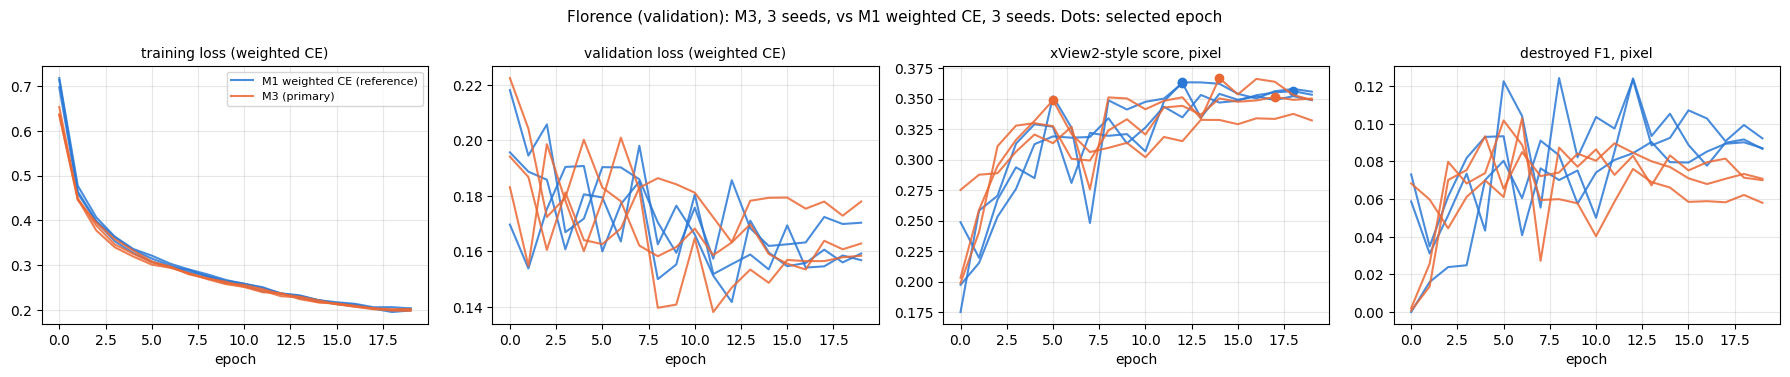

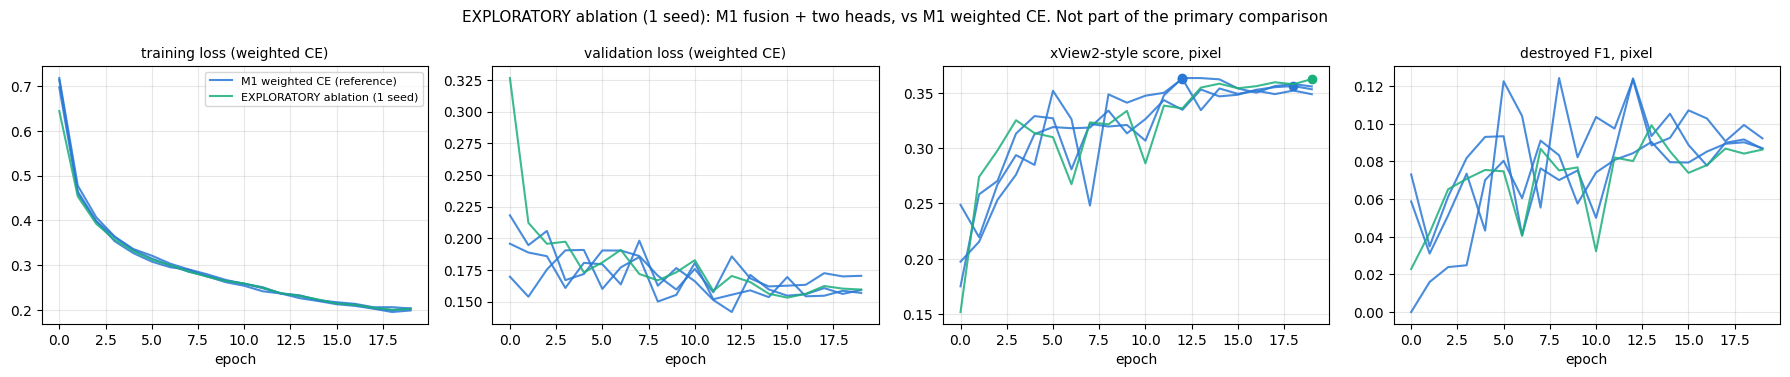

                        group                                     run  epoch  xview2_pixel_score  last_epoch_score  last_val_loss  last_train_loss
EXPLORATORY ablation (1 seed) exploratory_abl_m1fusion_dualhead_ce_s0     19              0.3623            0.3623         0.1595           0.2017
   M1 weighted CE (reference)                   m1_siamese_unet_ce_s0     12              0.3633            0.3557         0.1703           0.2029
   M1 weighted CE (reference)                   m1_siamese_unet_ce_s1     12              0.3626            0.3487         0.1568           0.1984
   M1 weighted CE (reference)                   m1_siamese_unet_ce_s2     18              0.3561            0.3531         0.1592           0.2028
                 M3 (primary)                      m3_msta_unet_ce_s0     17              0.3512            0.3499         0.1628           0.2000
                 M3 (primary)                      m3_msta_unet_ce_s1     14              0.3668            0.3488    

In [ ]:
import matplotlib.pyplot as plt
# Per-epoch training log of one run
def curves(run_dir):
    return pd.DataFrame([json.loads(l) for l in open(f"{run_dir}/metrics.jsonl")])
# Curves of the four new runs and the three M1 CE reference runs
CURV = []
for run, group, _, _, odir in RUNS:
    c = curves(f"{odir}/{run}"); c.insert(0, "run", run); c.insert(0, "group", group); CURV.append(c)
for s in range(3):
    c = curves(f"{CK}/m1_siamese_unet_ce_s{s}"); c.insert(0, "run", f"m1_siamese_unet_ce_s{s}"); c.insert(0, "group", "M1 weighted CE (reference)"); CURV.append(c)
CURV_DF = pd.concat(CURV, ignore_index=True)
cols = ["group", "run", "epoch", "train_loss", "val_loss", "xview2_pixel_score", "loc_f1", "dmg_f1_no_damage",
        "dmg_f1_minor", "dmg_f1_major", "dmg_f1_destroyed", "lr", "seconds"]
CURV_DF[cols].to_csv(out("results", "stage4_training_curves.csv"), index=False)
# Four panels: training loss, validation loss, pixel score and destroyed F1
PANELS = [("train_loss", "training loss (weighted CE)"), ("val_loss", "validation loss (weighted CE)"),
          ("xview2_pixel_score", "xView2-style score, pixel"), ("dmg_f1_destroyed", "destroyed F1, pixel")]
# One figure per comparison; dots mark each run's selected (best) epoch
def fig(groups, title, fname):
    f, ax = plt.subplots(1, 4, figsize=(18, 3.8))
    colors = {"M1 weighted CE (reference)": "#2a78d6", "M3 (primary)": "#eb6834", "EXPLORATORY ablation (1 seed)": "#1baf7a"}
    for g in groups:
        for run in CURV_DF[CURV_DF.group == g].run.unique():
            d = CURV_DF[CURV_DF.run == run]
            for a, (k, lab) in zip(ax, PANELS):
                a.plot(d.epoch, d[k], color=colors[g], lw=1.5, alpha=0.85, label=g if run.endswith("s0") and a is ax[0] else None)
                if k == "xview2_pixel_score":
                    bi = d[k].idxmax(); a.plot(d.loc[bi, "epoch"], d.loc[bi, k], "o", color=colors[g], ms=6)
    for a, (k, lab) in zip(ax, PANELS):
        a.set_title(lab, fontsize=10); a.set_xlabel("epoch"); a.grid(alpha=0.3)
    ax[0].legend(fontsize=8); f.suptitle(title, fontsize=11); f.tight_layout()
    f.savefig(out("figures", fname), dpi=200, bbox_inches="tight"); plt.show()
# Primary figure (M3 vs M1 CE) and a separate figure for the exploratory ablation
fig(["M1 weighted CE (reference)", "M3 (primary)"], "Florence (validation): M3, 3 seeds, vs M1 weighted CE, 3 seeds. Dots: selected epoch",
    "stage4_curves_M3_vs_M1ce.png")
fig(["M1 weighted CE (reference)", "EXPLORATORY ablation (1 seed)"],
    "EXPLORATORY ablation (1 seed): M1 fusion + two heads, vs M1 weighted CE. Not part of the primary comparison",
    "stage4_curves_EXPLORATORY_ablation.png")
# Best and last epoch of every run
BEST = CURV_DF.loc[CURV_DF.groupby("run")["xview2_pixel_score"].idxmax(), ["group", "run", "epoch", "xview2_pixel_score"]]
LASTE = CURV_DF[CURV_DF.epoch == 19][["run", "xview2_pixel_score", "val_loss", "train_loss"]].rename(
    columns={"xview2_pixel_score": "last_epoch_score", "val_loss": "last_val_loss", "train_loss": "last_train_loss"})
print(BEST.merge(LASTE, on="run").round(4).to_string(index=False))

## 11. Compute, preservation check and summary

In [ ]:
# Training time per run, from the launch log
SESS = [json.loads(l) for l in open(SESS_LOG)] if os.path.exists(SESS_LOG) else []
COMP = []
for run, group, *_ in RUNS:
    launches = [s for s in SESS if s["run"] == run]
    COMP.append({"run": run, "group": group, "launches": len(launches),
                 "resumed_launches": [f"from epoch {s['start_epoch']}" for s in launches if s["resumed"]],
                 "wall_hours_training": round(sum(s["wall_seconds"] for s in launches) / 3600, 3),
                 "epoch_seconds_logged_total_h": round(VERIFY[run]["epoch_seconds_logged_total"] / 3600, 3),
                 "median_epoch_s": float(np.median(curves(f"{dict((r, o) for r, _, _, _, o in RUNS)[run]}/{run}")["seconds"]))})
COMP_DF = pd.DataFrame(COMP)
COMP_DF.to_csv(out("results", "stage4_compute.csv"), index=False)
# Session length and an estimate of compute units (not read from Colab)
SESSION["session_end"] = datetime.datetime.now().isoformat(timespec="seconds")
sess_h = (datetime.datetime.fromisoformat(SESSION["session_end"]) - datetime.datetime.fromisoformat(SESSION["session_start"])).total_seconds() / 3600
# Nothing outside m3_experiments/ may have changed
AFTER = snapshot()
ch = {"added": sorted(set(AFTER) - set(BEFORE)), "removed": sorted(set(BEFORE) - set(AFTER)),
      "changed": sorted(k for k in set(BEFORE) & set(AFTER) if BEFORE[k] != AFTER[k])}
PRES = "NOTHING OUTSIDE m3_experiments CHANGED" if not any(ch.values()) else f"DIFFERENCES: {ch}"
# Summary of everything above, saved and printed
SUMMARY = {"session": {**SESSION, "this_session_hours": round(sess_h, 2),
                       "estimated_units_this_session (assumes ~4.8 units/h on L4; check Colab's Resources panel)": round(4.8 * sess_h, 1)},
           "nodata_loss_check": {k: NODATA[k] for k in NODATA if k != "crops"}, "nodata_crops": NODATA["crops"],
           "verification": VER_DF.drop(columns=["best_pt_sha256"]).to_dict(orient="records"),
           "launches": SESS, "compute": COMP,
           "florence_primary": prim[SHOW].round(4).to_dict(orient="records"),
           "florence_primary_mean_std": {"|".join(map(str, k)): v for k, v in AGG.round(4).T.stack().to_dict().items()} if len(AGG) else {},
           "florence_EXPLORATORY_ablation": abl[SHOW].round(4).to_dict(orient="records"),
           "attention_scales": SC_DF.round(4).to_dict(orient="records"),
           "attention_knockout": KO_DF.round(5).to_dict(orient="records"),
           "best_and_last_epoch": BEST.merge(LASTE, on="run").round(4).to_dict(orient="records"),
           "preservation": PRES}
jdump(SUMMARY, out("results", f"stage4_summary_{datetime.datetime.now():%Y%m%d_%H%M}.json"))
print(json.dumps(SUMMARY, indent=1, default=str))

{
 "session": {
  "session_start": "2026-11-20T16:03:22",
  "gpu": "NVIDIA L4",
  "session_end": "2026-11-20T21:04:44",
  "this_session_hours": 5.02,
  "estimated_units_this_session (assumes ~4.8 units/h on L4; check Colab's Resources panel)": 24.1
 },
 "nodata_loss_check": {
  "total_ignored_px": 1360934,
  "train-loss call SegLoss('ce') fp32": 0.7454668879508972,
  "decomposed fp32": 0.745466947555542,
  "CE fp64": 0.7454669758976584,
  "decomposed fp64": 0.7454669758976564,
  "building term / damage term (fp64)": [
   0.6609656445767876,
   0.0845013313208688
  ],
  "denominator decomposed / explicit sum w_y over non-ignored": [
   77638.68000000002,
   77638.68000000001
  ],
  "|decomposed - CE| fp64": 1.9984014443252818e-15,
  "rel |fp32 call - decomposed fp32|": 7.995612647428104e-08,
  "loss change after altering outputs at ignored pixels (fp64, CPU)": 0.0,
  "loss change after altering outputs at ignored pixels (fp32, GPU; reduction order may vary)": 5.960464477539063e-08,
  "P

## End of notebook
Releases the Colab runtime so it stops using compute units.

In [ ]:
# Release the Colab runtime
from google.colab import runtime
runtime.unassign()